# EDA de SPHEREx: qué hay, cómo es un archivo y qué cambia entre fechas

Notebook para **entender los datos** antes (y mientras) se construye el visor. Usa las mismas funciones que el
prototipo (`spherex.py`), así que lo que se ve aquí es exactamente lo que ve la interfaz.

1. **Inventario**: cuántas observaciones hay en una posición, en qué fechas y en qué bandas.
2. **Anatomía de un recorte**: las 6 extensiones del FITS, el fondo zodiacal, las marcas de contaminación y la
   longitud de onda por píxel.
3. **El filtro lineal variable**: por qué el brillo "salta" entre exposiciones sin que nada cambie.
4. **Secuencia temporal y resta**: varias imágenes del mismo trozo de cielo, alineadas, y su diferencia.
5. **Comprobación del movimiento**: ¿el objeto está donde predice su movimiento propio?

No baja archivos completos: solo recortes, que quedan en `data/cache/prototipo/` (fuera de git).

In [1]:
import sys, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from astropy.io import fits
from astropy.time import Time

AQUI = Path.cwd()
if not (AQUI / "spherex.py").exists():          # por si se abre desde la raíz del repo
    AQUI = AQUI / "prototipos" / "rango_fechas"
sys.path.insert(0, str(AQUI))
import spherex

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower", "image.interpolation": "nearest"})

## 0. Elegir el campo

Los cinco objetos de prueba del desafío están en `data/campos_de_prueba.yml`. Cambia `CAMPO` y vuelve a correr.

| id | qué se espera |
|---|---|
| `barnard` | movimiento grande y brillante: el caso más claro |
| `wise_0855` | movimiento grande pero débil: hace falta sumar exposiciones (`POR_VISITA ≥ 4`) |
| `eps_ind_b` | movimiento, objeto rojo (bandas 5–6) |
| `rw_aur`, `r_dra` | cambian de brillo **sin** moverse (controles) |

In [2]:
CAMPO = "barnard"
BANDA = None          # None = la recomendada en el .yml
INICIO, FIN = "2025-04-01", Time.now().isot[:10]
SIZE = 0.1            # grados
POR_VISITA = 3        # exposiciones sumadas por visita
# Ventana (px) para medir el desplazamiento en la sección 5. Objetos débiles: chica (5), para que las
# estrellas quietas vecinas no tiren la medida hacia 0. Brillantes: grande (15), para abarcar la PSF entera.
# Comprobado el 14-nov-2026: WISE 0855 -> 5 ; Barnard y RW Aur -> 15. eps Ind B y R Dra: sin comprobar.
VENTANA = {"wise_0855": 5}.get(CAMPO, 15)

campos = {c["id"]: c for c in yaml.safe_load((spherex.RAIZ / "data" / "campos_de_prueba.yml").read_text())["campos"]}
c = campos[CAMPO]
BANDA = BANDA or c["banda_recomendada"]

def posicion(c, anio):
    """Propaga la posición J2000 del catálogo con el movimiento propio (lineal, sin paralaje)."""
    dt = anio - 2000.0
    dec = c["dec_deg"] + c["pmdec"] * dt / 3.6e6
    ra = c["ra_deg"] + c["pmra"] * dt / 3.6e6 / math.cos(math.radians(c["dec_deg"]))
    return ra % 360, dec

anio_medio = (Time(INICIO).decimalyear + Time(FIN).decimalyear) / 2
RA, DEC = posicion(c, anio_medio)
print(f"{c['nombre']}: banda {BANDA}, centro propagado a {anio_medio:.2f} -> RA {RA:.6f}, Dec {DEC:.6f}")
print(f"Movimiento propio: {math.hypot(c['pmra'], c['pmdec'])/1000:.2f} arcsec/año "
      f"= {math.hypot(c['pmra'], c['pmdec'])/1000/spherex.ESCALA_ARCSEC:.2f} píxeles/año")

Estrella de Barnard: banda 2, centro propagado a 2026.06 -> RA 269.446256, Dec 4.768370
Movimiento propio: 10.39 arcsec/año = 1.69 píxeles/año


## 1. Inventario: qué hay en esta posición

Una consulta por banda (barata: no baja imágenes).

In [3]:
filas = []
for b in range(1, 7):
    obs, _ = spherex.buscar(RA, DEC, b, INICIO, FIN)
    for o in obs:
        filas.append(dict(banda=b, obs_id=o.obs_id, coleccion=o.coleccion, mjd=o.mjd,
                          fecha=pd.Timestamp(Time(o.mjd, format="mjd").datetime), url=o.access_url))
inv = pd.DataFrame(filas).sort_values("mjd")
visitas = {b: spherex.agrupar_visitas([o for o in spherex.buscar(RA, DEC, b, INICIO, FIN)[0]]) for b in [BANDA]}

print(f"{len(inv)} observaciones en total")
display(inv.groupby(["banda", "coleccion"]).size().unstack(fill_value=0))

364 observaciones en total


coleccion,spherex_dr1,spherex_qr3
banda,,
1,42,18
2,37,25
3,42,19
4,41,18
5,37,25
6,41,19


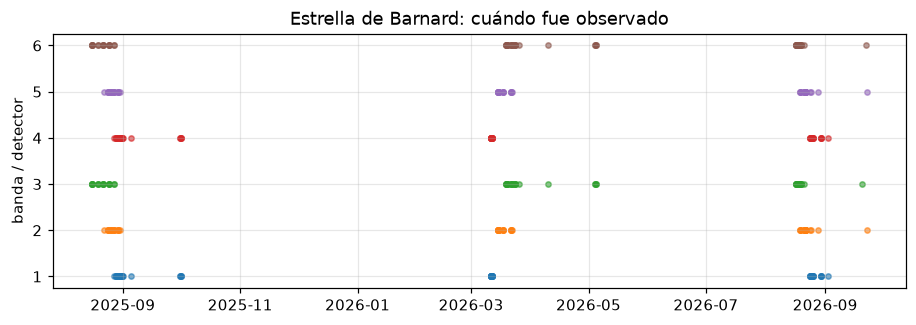

Banda 2: 4 visitas
  visita 1: 2025-08-21 -> 2025-08-30  (18 exposiciones, spherex_dr1)
  visita 2: 2026-03-15 -> 2026-03-22  (19 exposiciones, spherex_dr1)
  visita 3: 2026-08-18 -> 2026-08-28  (24 exposiciones, spherex_qr3)
  visita 4: 2026-09-22 -> 2026-09-22  (1 exposiciones, spherex_qr3)
Base temporal: 1.09 años -> desplazamiento esperado 11.3 arcsec = 1.84 píxeles


In [4]:
fig, ax = plt.subplots(figsize=(10, 3))
for b, g in inv.groupby("banda"):
    ax.scatter(g["fecha"], np.full(len(g), b), s=12, alpha=.6)
ax.set_yticks(range(1, 7)); ax.set_ylabel("banda / detector"); ax.set_title(f"{c['nombre']}: cuándo fue observado")
ax.grid(alpha=.3); plt.show()

v = visitas[BANDA]
print(f"Banda {BANDA}: {len(v)} visitas")
for i, vv in enumerate(v):
    print(f"  visita {i+1}: {vv[0].iso[:10]} -> {vv[-1].iso[:10]}  ({len(vv)} exposiciones, {vv[0].coleccion})")
base = (v[-1][0].mjd - v[0][0].mjd) / 365.25
print(f"Base temporal: {base:.2f} años -> desplazamiento esperado "
      f"{math.hypot(c['pmra'], c['pmdec'])/1000*base:.1f} arcsec = "
      f"{math.hypot(c['pmra'], c['pmdec'])/1000*base/spherex.ESCALA_ARCSEC:.2f} píxeles")

**Qué mirar:** SPHEREx vuelve a cada zona cada ~6 meses y, en cada visita, la observa varias veces en pocos días.
Para ver movimiento importa la **base temporal** (primera → última visita), no el número de exposiciones.

## 2. Anatomía de un recorte

Bajamos **un** recorte (el de la visita del medio) y miramos todo lo que trae.

In [5]:
o = v[len(v)//2][len(v[len(v)//2])//2]
ruta = spherex.bajar_recorte(o, RA, DEC, SIZE)
print(o.obs_id, o.iso, f"{ruta.stat().st_size/1e6:.1f} MB")
hd = fits.open(ruta)
hd.info()
h = hd["IMAGE"].header
for k in ["DATE-OBS", "MJD-OBS", "DETECTOR", "OBSID", "BUNIT", "CTYPE1", "CTYPE2", "XPOSURE"]:
    print(f"{k:9s} = {h.get(k, hd['FLAGS'].header.get(k))}")
print(f"\nPeso de cada parte: " + ", ".join(f"{x.name} {x.filebytes()/1e3:.0f} KB" for x in hd[1:]))

2026W34_2A_0233_1D2 2026-08-21T15:35:01Z 4.0 MB
Filename: data/cache/prototipo/cutouts/b5aab75b3624b1ae7a6e4cd14daefed7f038a8a2.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       292   (59, 59)   float32   
  2  FLAGS         1 ImageHDU       185   (59, 59)   int32   
  3  VARIANCE      1 ImageHDU       119   (59, 59)   float32   
  4  ZODI          1 ImageHDU       122   (59, 59)   float32   
  5  EPSF          1 BinTableHDU     56   441R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [11J, 11J, 242E]   


DATE-OBS  = 2026-08-21T15:35:01.084
MJD-OBS   = 61273.649318102
DETECTOR  = 2
OBSID     = 2026W34_2A_0233_1
BUNIT     = MJy / sr
CTYPE1    = RA---TAN-SIP
CTYPE2    = DEC--TAN-SIP
XPOSURE   = 113.5826

Peso de cada parte: IMAGE 40 KB, FLAGS 32 KB, VARIANCE 26 KB, ZODI 26 KB, EPSF 3868 KB, WCS-WAVE 6 KB


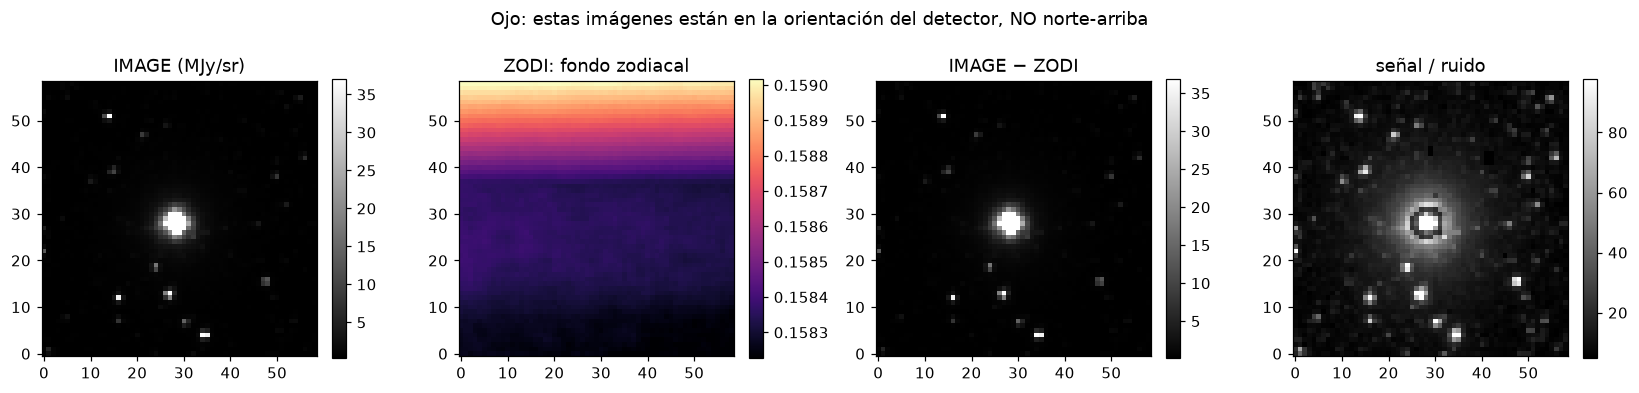

Fondo zodiacal medio: 0.158 MJy/sr | señal neta mediana: 0.242 | píxeles NaN: 0.1 % (saturados o sin dato)


In [6]:
img, zodi, var = (hd[n].data.astype(float) for n in ("IMAGE", "ZODI", "VARIANCE"))
neto = img - zodi
snr = neto / np.sqrt(var)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, d, t in zip(axs, [img, zodi, neto, snr], ["IMAGE (MJy/sr)", "ZODI: fondo zodiacal", "IMAGE − ZODI", "señal / ruido"]):
    lo, hi = np.nanpercentile(d, [1, 99.5])
    im = ax.imshow(d, vmin=lo, vmax=hi, cmap="gray" if "ZODI:" not in t else "magma")
    ax.set_title(t); plt.colorbar(im, ax=ax, fraction=.046)
plt.suptitle("Ojo: estas imágenes están en la orientación del detector, NO norte-arriba"); plt.tight_layout(); plt.show()

print(f"Fondo zodiacal medio: {np.nanmedian(zodi):.3f} MJy/sr | señal neta mediana: {np.nanmedian(neto):.3f} | "
      f"píxeles NaN: {np.isnan(img).mean()*100:.1f} % (saturados o sin dato)")

**Qué mirar:** el fondo zodiacal (luz del Sol dispersada por el polvo del sistema solar) es casi todo el brillo
del cielo en el infrarrojo y **no viene restado** en `IMAGE`. Restarlo es lo primero.

### Marcas de contaminación (FLAGS)

Los nombres de cada bit vienen en la propia cabecera (`MSKNnnnn`).

,bit,nombre,fraccion,tipo
0,0,TRANSIENT,1.67 %,se enmascara
1,1,OVERFLOW,0.2 %,contaminación (se muestra)
2,2,SUR_ERROR,1.35 %,se enmascara
3,6,NONFUNC,0.06 %,se enmascara
7,11,COLD,0.03 %,se enmascara
11,17,PERSIST,0.06 %,contaminación (se muestra)
14,21,SOURCE,100.0 %,informativo
19,26,BLOOM,1.49 %,contaminación (se muestra)
21,28,HALO,0.98 %,contaminación (se muestra)


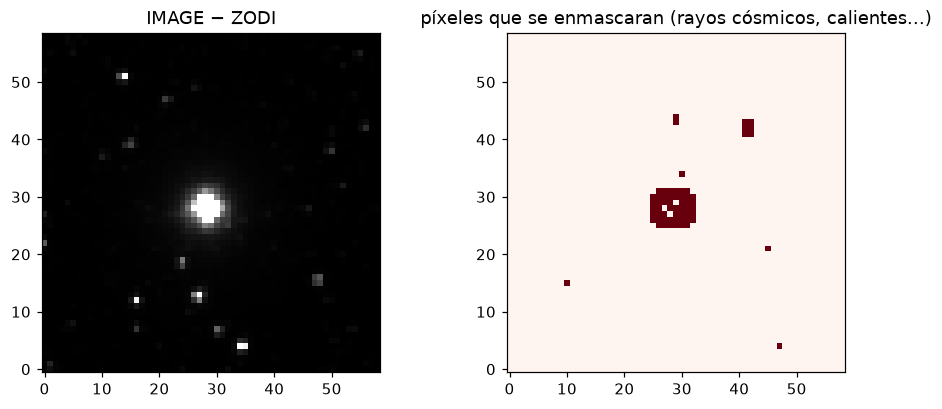

In [7]:
defs = spherex.definiciones_flags(hd["FLAGS"].header)
f = hd["FLAGS"].data.astype(np.int64)
tabla = pd.DataFrame([dict(bit=b, nombre=n, fraccion=((f >> b) & 1).mean(),
                           tipo="informativo" if n in spherex.BITS_INFORMATIVOS else
                                ("se enmascara" if n in spherex.BITS_ENMASCARAR else "contaminación (se muestra)"))
                      for b, n in sorted(defs.items())])
tabla = tabla[tabla.fraccion > 0]
display(tabla.assign(fraccion=(tabla.fraccion * 100).round(2).astype(str) + " %"))

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
malos = np.zeros(f.shape, bool)
for b, n in defs.items():
    if n in spherex.BITS_ENMASCARAR: malos |= ((f >> b) & 1).astype(bool)
axs[0].imshow(neto, vmin=np.nanpercentile(neto, 1), vmax=np.nanpercentile(neto, 99.5), cmap="gray"); axs[0].set_title("IMAGE − ZODI")
axs[1].imshow(malos, cmap="Reds"); axs[1].set_title("píxeles que se enmascaran (rayos cósmicos, calientes…)")
plt.show()

**Ojo:** el bit `SOURCE` ("píxel asociado a una fuente conocida") puede salir en casi el 100 % de los píxeles de un
campo poblado. **No es contaminación**: si se cuenta como tal, todo parece inservible.

## 3. El filtro lineal variable: la longitud de onda cambia **dentro** de cada imagen

La tabla `WCS-WAVE` da la λ en una rejilla de puntos de control del detector. La interpolamos a cada píxel del recorte.

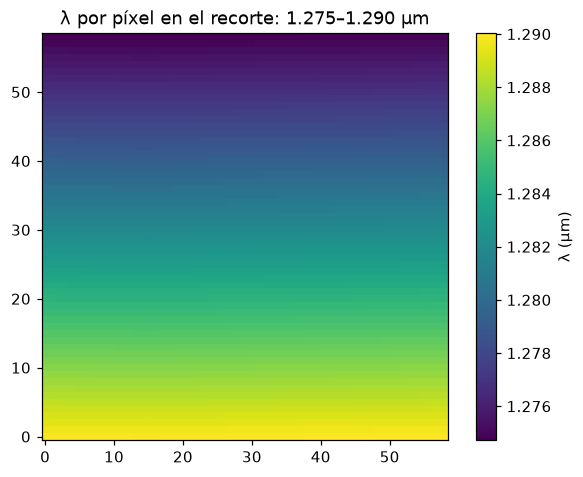

En el centro: λ = 1.2822 µm, ancho de banda 30.5 nm


In [8]:
def mapa_lambda(hd):
    h = hd["IMAGE"].header; t = hd["WCS-WAVE"].data
    xs, ys = np.asarray(t["X"][0], float), np.asarray(t["Y"][0], float)
    vals = np.asarray(t["VALUES"][0], float)
    ny, nx = hd["IMAGE"].data.shape
    py_, px_ = np.mgrid[1:ny+1, 1:nx+1]                      # 1-based, como FITS
    cx = (px_ - h["CRPIX1W"]) * h.get("CDELT1W", 1) + h.get("CRVAL1W", 1)
    cy = (py_ - h["CRPIX2W"]) * h.get("CDELT2W", 1) + h.get("CRVAL2W", 1)
    fx, fy = np.interp(cx, xs, np.arange(len(xs))), np.interp(cy, ys, np.arange(len(ys)))
    from scipy.ndimage import map_coordinates
    return map_coordinates(vals[..., 0], [fy, fx], order=1), map_coordinates(vals[..., 1], [fy, fx], order=1)

lam, anch = mapa_lambda(hd)
im = plt.imshow(lam, cmap="viridis"); plt.colorbar(im, label="λ (µm)")
plt.title(f"λ por píxel en el recorte: {lam.min():.3f}–{lam.max():.3f} µm"); plt.show()
print(f"En el centro: λ = {spherex.longitud_onda_centro(hd)[0]:.4f} µm, ancho de banda {spherex.longitud_onda_centro(hd)[1]*1000:.1f} nm")

Ahora la consecuencia: la **misma estrella** medida en distintas exposiciones de la banda cae cada vez en un sitio
distinto del detector, y por tanto en una λ distinta. Medimos su flujo (apertura simple) en cada exposición.

Usamos la estrella brillante **no saturada** más cercana al centro (el objeto de prueba puede estar saturado, como
Barnard, y entonces su flujo no se puede medir). El efecto del filtro es el mismo para cualquier estrella.

Estrella de referencia en el píxel (np.int64(30), np.int64(45))


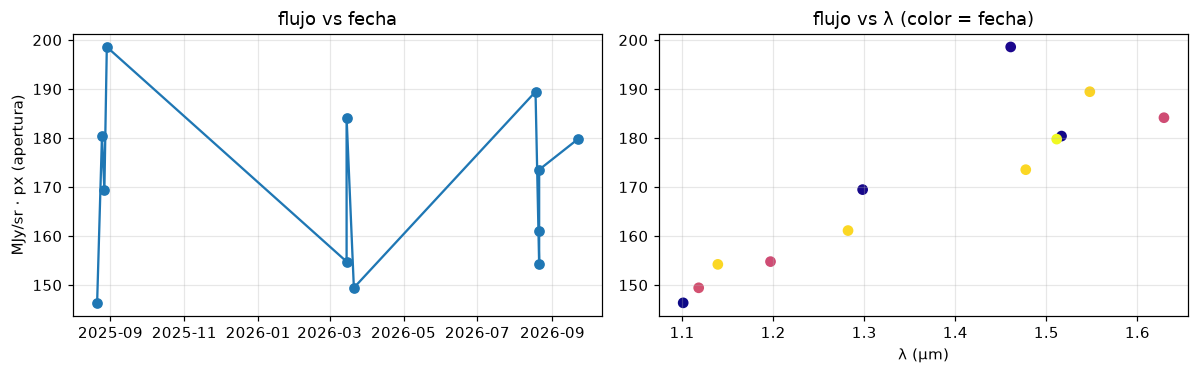

In [9]:
N_ESPECTRO = 12
todas = [x for vv in v for x in vv]
muestra = [todas[i] for i in np.unique(np.linspace(0, len(todas)-1, N_ESPECTRO).astype(int))]
n_px = int(math.ceil(SIZE * 3600 / spherex.ESCALA_ARCSEC))

def flujo_apertura(datos, x0, y0, r=2.0):
    yy, xx = np.mgrid[0:n_px, 0:n_px]
    ap = (xx - x0)**2 + (yy - y0)**2 <= r**2
    an = ((xx - x0)**2 + (yy - y0)**2 > (r+3)**2) & ((xx - x0)**2 + (yy - y0)**2 <= (r+6)**2)
    if np.isnan(datos[ap]).mean() > 0.1:      # saturada o enmascarada: no se puede medir
        return np.nan
    return np.nansum(datos[ap] - np.nanmedian(datos[an]))

fgs = [spherex.procesar(spherex.bajar_recorte(x, RA, DEC, SIZE), x, RA, DEC, n_px) for x in muestra]

# Elegir la estrella: máximo local brillante, sin NaN en su apertura EN NINGUNA exposición, lejos del borde.
from scipy.ndimage import maximum_filter
ref = np.nanmedian(np.stack([f_.datos for f_ in fgs]), axis=0)
ref0 = np.nan_to_num(ref - np.nanmedian(ref))
picos = (ref0 == maximum_filter(ref0, size=5)) & (ref0 > np.nanpercentile(ref0, 99))
yy, xx = np.nonzero(picos)
cands = sorted([(ref0[y, x], x, y) for y, x in zip(yy, xx) if 6 <= x < n_px-6 and 6 <= y < n_px-6], reverse=True)
estrella = next(((x, y) for v_, x, y in cands
                 if all(np.isfinite(flujo_apertura(f_.datos, x, y)) for f_ in fgs)), None)
print("Estrella de referencia en el píxel", estrella)

med = pd.DataFrame([dict(fecha=x.iso[:10], lam=f_.lambda_um,
                         flujo=flujo_apertura(f_.datos, *estrella) if estrella else np.nan)
                    for x, f_ in zip(muestra, fgs)])

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(pd.to_datetime(med.fecha), med.flujo, "o-"); axs[0].set_title("flujo vs fecha"); axs[0].set_ylabel("MJy/sr · px (apertura)")
axs[1].scatter(med.lam, med.flujo, c=pd.to_datetime(med.fecha).astype("int64"), cmap="plasma"); axs[1].set_title("flujo vs λ (color = fecha)")
axs[1].set_xlabel("λ (µm)")
for a in axs: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Qué mirar:** si el flujo se ordena mejor por λ que por fecha, los "cambios de brillo" son del filtro y no del
objeto. Por eso el visor muestra la λ de cada fotograma y avisa cuando difieren. (Fotometría de apertura simple:
indicativa, no científica.)

## 4. Secuencia temporal: varias imágenes alineadas y su diferencia

Cada recorte viene de un apuntado distinto, con el detector girado de otra forma. Para compararlos hay que
**reproyectarlos** a una rejilla común norte-arriba. Esto es lo que hace `spherex.fotogramas()`.

4 fotogramas de 4 visitas, 10 recortes
AVISO: Las épocas están a longitudes de onda distintas (1.28–1.51 µm): parte del cambio de brillo puede deberse al filtro, no al objeto.


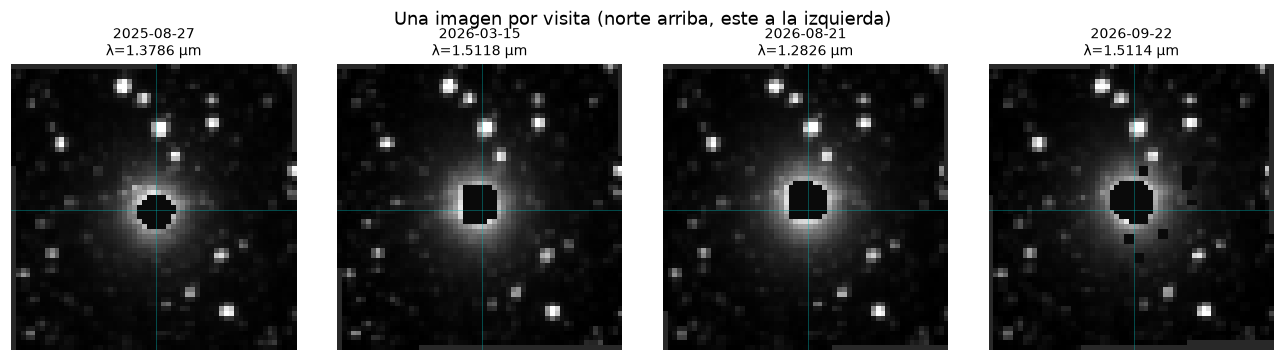

In [10]:
r = spherex.fotogramas(RA, DEC, BANDA, INICIO, FIN, SIZE, max_visitas=8, por_visita=POR_VISITA)
print(f"{r['n_frames']} fotogramas de {r['n_visits_available']} visitas, {r['n_cutouts']} recortes")
for w_ in r["warnings"]: print("AVISO:", w_)

import base64, io
from PIL import Image
def a_img(uri): return np.asarray(Image.open(io.BytesIO(base64.b64decode(uri.split(",")[1]))))

fr = r["frames"]
fig, axs = plt.subplots(1, len(fr), figsize=(3*len(fr), 3.3))
for ax, f_ in zip(np.atleast_1d(axs), fr):
    ax.imshow(a_img(f_["png"]), origin="upper", cmap="gray")
    ax.set_title(f"{f_['t'][:10]}\nλ={f_['wavelength_um']} µm", fontsize=9); ax.axis("off")
    ax.axhline(r["n_pixels"]/2, color="c", lw=.4, alpha=.6); ax.axvline(r["n_pixels"]/2, color="c", lw=.4, alpha=.6)
plt.suptitle("Una imagen por visita (norte arriba, este a la izquierda)"); plt.tight_layout(); plt.show()

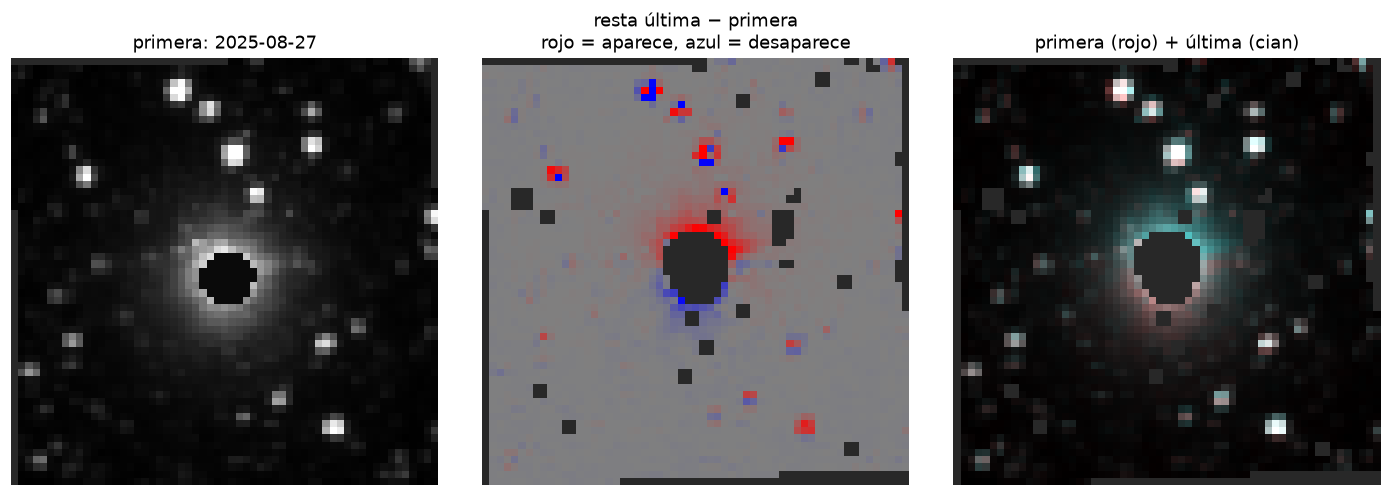

La última se escaló ×0.9826 antes de restar para igualar el flujo de las fuentes brillantes.


In [11]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
axs[0].imshow(a_img(fr[0]["png"]), origin="upper", cmap="gray"); axs[0].set_title(f"primera: {fr[0]['t'][:10]}")
axs[1].imshow(a_img(r["diff_png"]), origin="upper"); axs[1].set_title("resta última − primera\nrojo = aparece, azul = desaparece")
axs[2].imshow(a_img(r["color_png"]), origin="upper"); axs[2].set_title("primera (rojo) + última (cian)")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()
print(f"La última se escaló ×{r['diff_scale_factor']} antes de restar para igualar el flujo de las fuentes brillantes.")

### Resta entre visitas consecutivas

La resta primera→última maximiza el desplazamiento. Las restas consecutivas muestran **cuándo** cambió algo.
Aquí trabajamos con los datos numéricos (no los PNG) para tener una escala común.

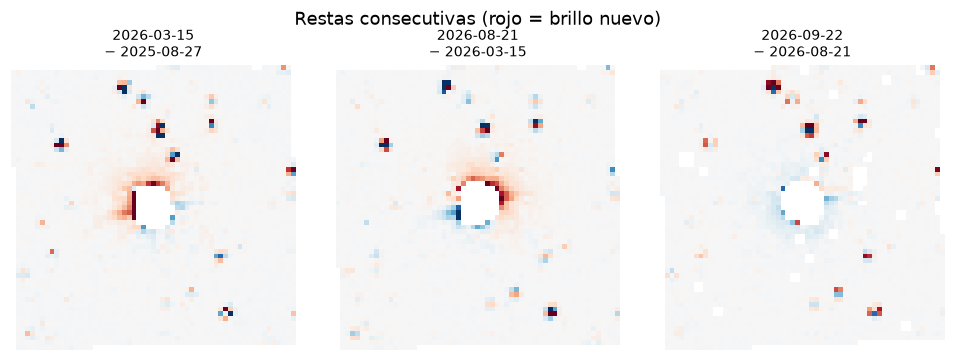

In [12]:
grupos = spherex.elegir_fotogramas(spherex.agrupar_visitas(spherex.buscar(RA, DEC, BANDA, INICIO, FIN)[0]), 8, POR_VISITA)
apilados = [spherex.apilar([spherex.procesar(spherex.bajar_recorte(x, RA, DEC, SIZE), x, RA, DEC, n_px) for x in g]) for g in grupos]
planos = [a.datos - np.nanmedian(a.datos) for a in apilados]
difs = [planos[i+1] - planos[i] for i in range(len(planos)-1)]
lim = np.nanpercentile(np.abs(np.concatenate([d[np.isfinite(d)] for d in difs])), 99.5)
fig, axs = plt.subplots(1, len(difs), figsize=(3*len(difs), 3.3))
for ax, d, i in zip(np.atleast_1d(axs), difs, range(len(difs))):
    ax.imshow(d, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"{apilados[i+1].obs.iso[:10]}\n− {apilados[i].obs.iso[:10]}", fontsize=9); ax.axis("off")
plt.suptitle("Restas consecutivas (rojo = brillo nuevo)"); plt.tight_layout(); plt.show()

**Ojo al leer las restas:** las estrellas quietas también dejan pequeños pares rojo/azul. Se deben a que cada
visita está a otra λ (la PSF cambia de forma) y a errores de alineación de una fracción de píxel. Lo que indica
movimiento real es un par **más marcado que el de las estrellas vecinas** y en la dirección esperada.

## 5. ¿Se movió lo que predice su movimiento propio?

Tomamos una ventana (`VENTANA`, ver configuración) alrededor del objeto en la **primera** visita y buscamos el desplazamiento (subpíxel) que mejor
la superpone con cada visita posterior. Ajustamos también un factor de brillo, porque cada visita está a otra λ.
Comparamos ese desplazamiento medido con el que predice el movimiento propio del catálogo.

Si coinciden, la alineación (WCS + reproyección) es correcta y lo que se ve en el parpadeo es movimiento real.
(Comprobación, no astrometría: no corrige paralaje y usa una ventana simple.)

,fecha,años,ventana_px,pred_dx,pred_dy,med_dx,med_dy,error_arcsec
0,2026-03-15,0.55,15,0.07,0.92,-0.62,0.40,5.33
1,2026-08-21,0.98,15,0.13,1.66,0.14,1.44,1.35
2,2026-09-22,1.07,15,0.14,1.81,0.34,1.50,2.25


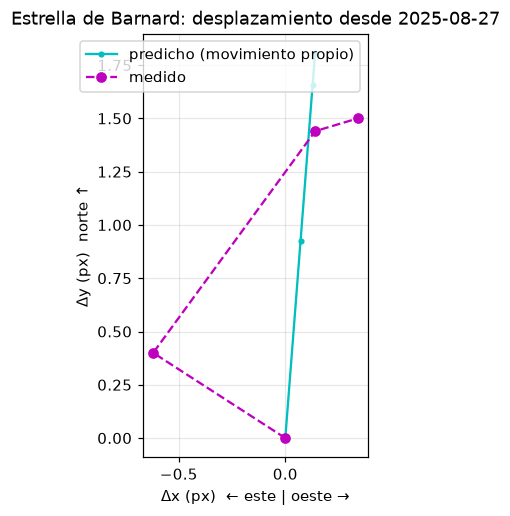

En x, valores positivos = hacia el OESTE, porque la imagen tiene el este a la izquierda.


In [13]:
from scipy.ndimage import shift as desplazar

def medir_desplazamiento(ref, img, x0, y0, medias=None, rango=4.0):
    """(dx, dy) en píxeles tal que img ≈ a · ref desplazada (dx, dy), en una ventana centrada en (x0, y0).
    Tamaño según VENTANA (ver celda de configuración). Si no hay bastantes píxeles válidos
    (núcleo saturado = NaN), se agranda."""
    medias = medias or (VENTANA // 2, VENTANA // 2 + 2, VENTANA // 2 + 4)
    for media in medias:
        r = _medir(ref, img, x0, y0, media, rango)
        if r is not None:
            return (*r, 2 * media + 1)
    return (np.nan, np.nan, None)

def _medir(ref, img, x0, y0, media, rango):
    ys, xs = slice(int(y0) - media, int(y0) + media + 1), slice(int(x0) - media, int(x0) + media + 1)
    b = img[ys, xs]
    def coste(dx, dy):
        s = desplazar(np.nan_to_num(ref), (dy, dx), order=1, cval=0)[ys, xs]
        m = desplazar(np.isfinite(ref).astype(float), (dy, dx), order=0, cval=0)[ys, xs] > 0
        m &= np.isfinite(b)
        if m.sum() < 0.6 * b.size: return np.inf
        a = (s[m] @ b[m]) / max(s[m] @ s[m], 1e-12)
        return np.mean((b[m] - a * s[m]) ** 2)
    mejor = (0.0, 0.0); paso = 0.5; centro = (0.0, 0.0)
    for paso, alcance in [(0.5, rango), (0.1, 0.6), (0.02, 0.12)]:     # grueso -> fino
        rej = np.arange(-alcance, alcance + 1e-9, paso)
        costes = {(centro[0] + dx, centro[1] + dy): coste(centro[0] + dx, centro[1] + dy) for dx in rej for dy in rej}
        centro = min(costes, key=costes.get)
        if not np.isfinite(costes[centro]): return None
    return centro

w = spherex.wcs_destino(RA, DEC, n_px)
t0 = Time(apilados[0].obs.mjd, format="mjd").decimalyear
x_ref, y_ref = w.wcs_world2pix(*posicion(c, t0), 0)
filas = []
for a, p in zip(apilados[1:], planos[1:]):
    t = Time(a.obs.mjd, format="mjd").decimalyear
    xp, yp = w.wcs_world2pix(*posicion(c, t), 0)
    dx, dy, ventana = medir_desplazamiento(planos[0], p, x_ref, y_ref)
    filas.append(dict(fecha=a.obs.iso[:10], años=round(t - t0, 2),
                      ventana_px=ventana, pred_dx=float(xp - x_ref), pred_dy=float(yp - y_ref), med_dx=dx, med_dy=dy,
                      error_arcsec=math.hypot(dx - (xp - x_ref), dy - (yp - y_ref)) * spherex.ESCALA_ARCSEC))
mov = pd.DataFrame(filas)
display(mov.round(2))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, *mov.pred_dx], [0, *mov.pred_dy], "c.-", label="predicho (movimiento propio)")
ax.plot([0, *mov.med_dx], [0, *mov.med_dy], "mo--", label="medido")
ax.set_xlabel("Δx (px)  ← este | oeste →"); ax.set_ylabel("Δy (px)  norte ↑")
ax.set_aspect("equal"); ax.grid(alpha=.3); ax.legend(); ax.set_title(f"{c['nombre']}: desplazamiento desde {apilados[0].obs.iso[:10]}")
plt.show()
print("En x, valores positivos = hacia el OESTE, porque la imagen tiene el este a la izquierda.")

**Cómo leerlo:** si los puntos medidos siguen a los predichos con error de menos de ~1 píxel (6″), la herramienta
muestra movimiento real. En los controles (RW Aur, R Dra) lo predicho y lo medido deben quedarse en ~0.

---
*This publication makes use of data products from the Spectro-Photometer for the History of the Universe, Epoch of
Reionization and Ices Explorer (SPHEREx), which is a joint project of the Jet Propulsion Laboratory and the California
Institute of Technology, and is funded by the National Aeronautics and Space Administration.*